# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Adult Dataset](https://www.kaggle.com/datasets/uciml/adult-census-income)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('adult.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


## last Five row

In [4]:
df.tail()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


## Shape of our dataset

In [5]:
df.shape

(32561, 15)

## List out all columns

In [6]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

age                int64
workclass         object
fnlwgt             int64
education         object
education.num      int64
marital.status    object
occupation        object
relationship      object
race              object
sex               object
capital.gain       int64
capital.loss       int64
hours.per.week     int64
native.country    object
income            object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


## Check Null Value

In [9]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(24)

## Summary

In [11]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

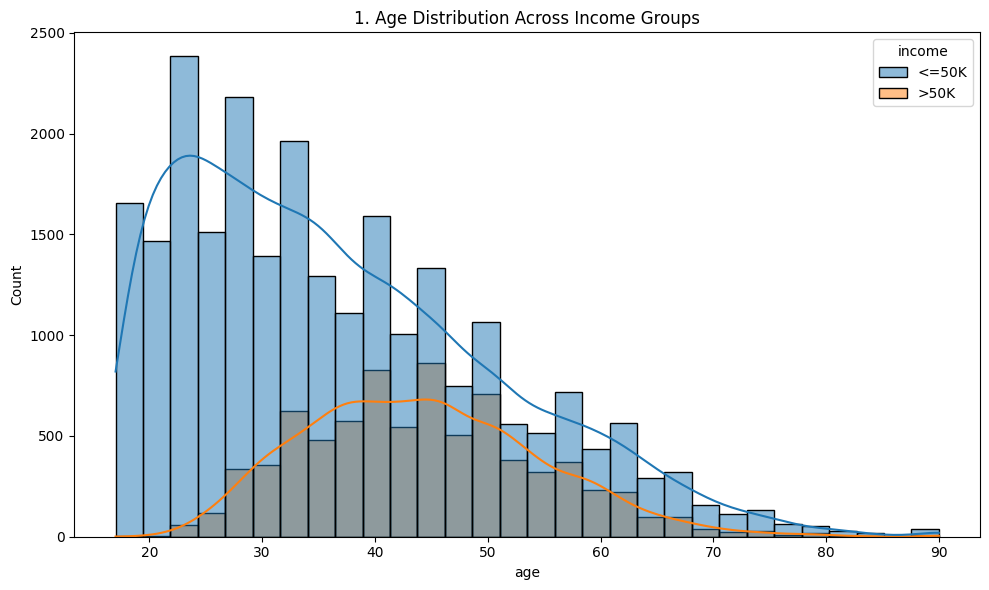

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='age', hue='income', bins=30, kde=True, multiple='layer')
plt.title(f'{plot_no}. Age Distribution Across Income Groups')
show_fig()
plot_no += 1

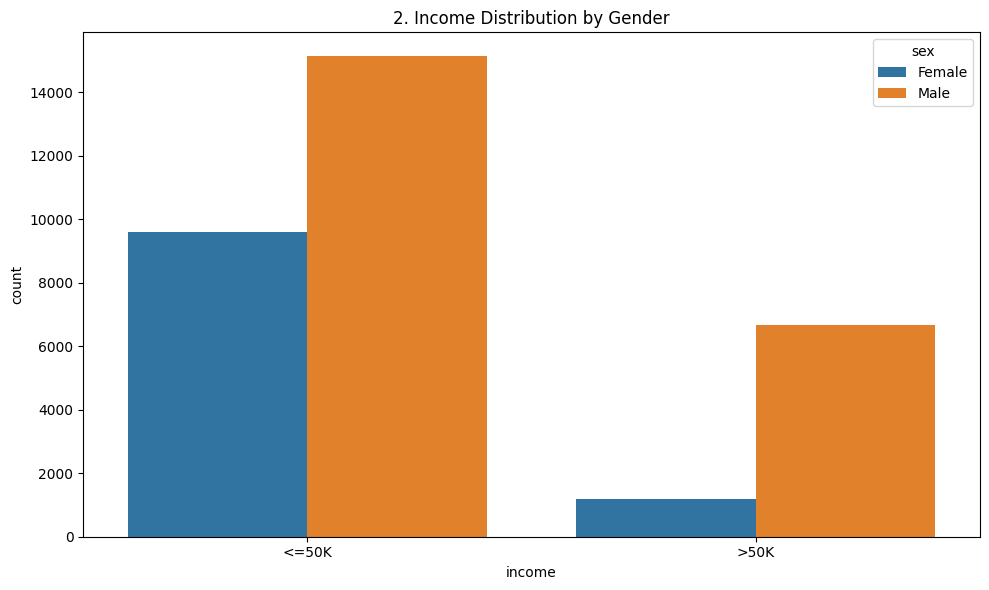

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='income', hue='sex')
plt.title(f'{plot_no}. Income Distribution by Gender')
show_fig()
plot_no += 1

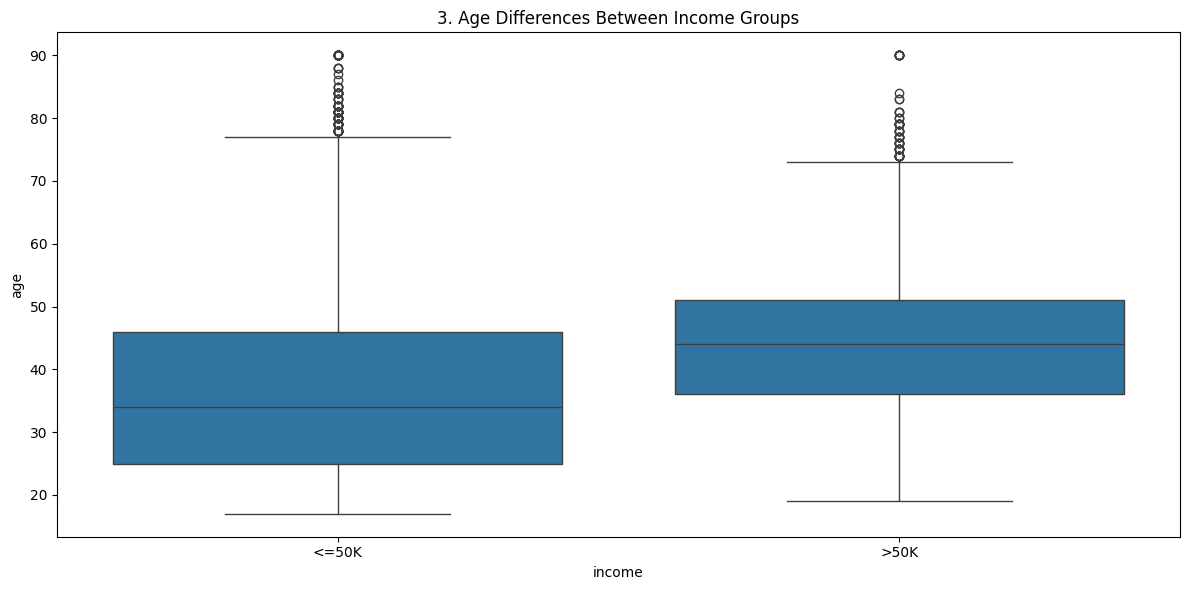

In [15]:
fig = plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='income', y='age')
plt.title(f'{plot_no}. Age Differences Between Income Groups')
show_fig()
plot_no += 1

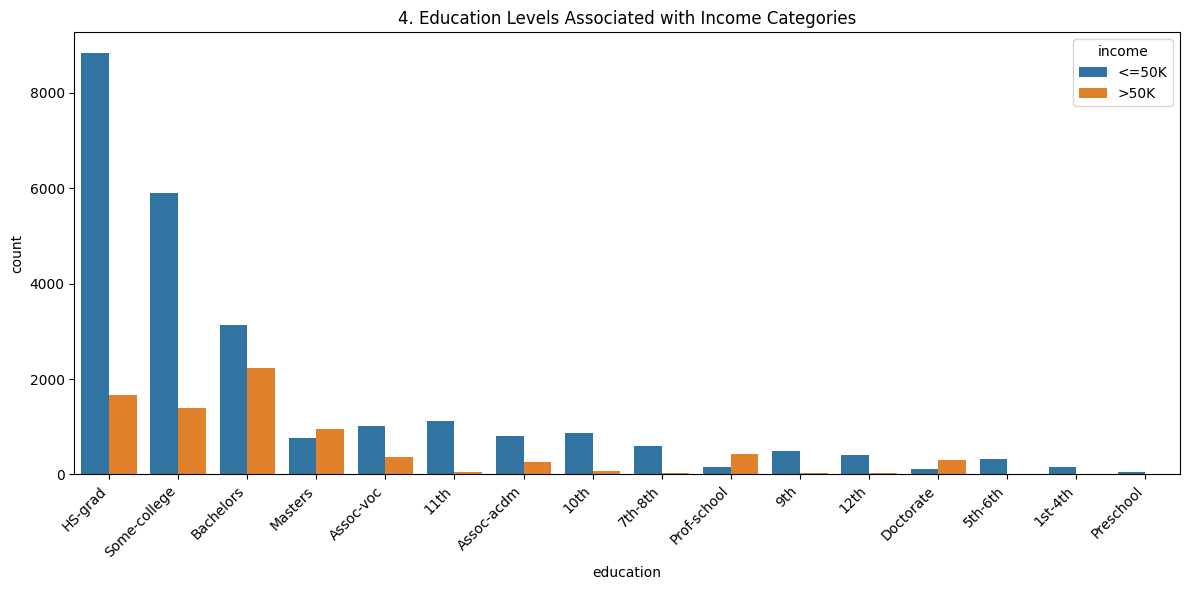

In [16]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='education', hue='income', order=df['education'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Education Levels Associated with Income Categories')
show_fig()
plot_no += 1

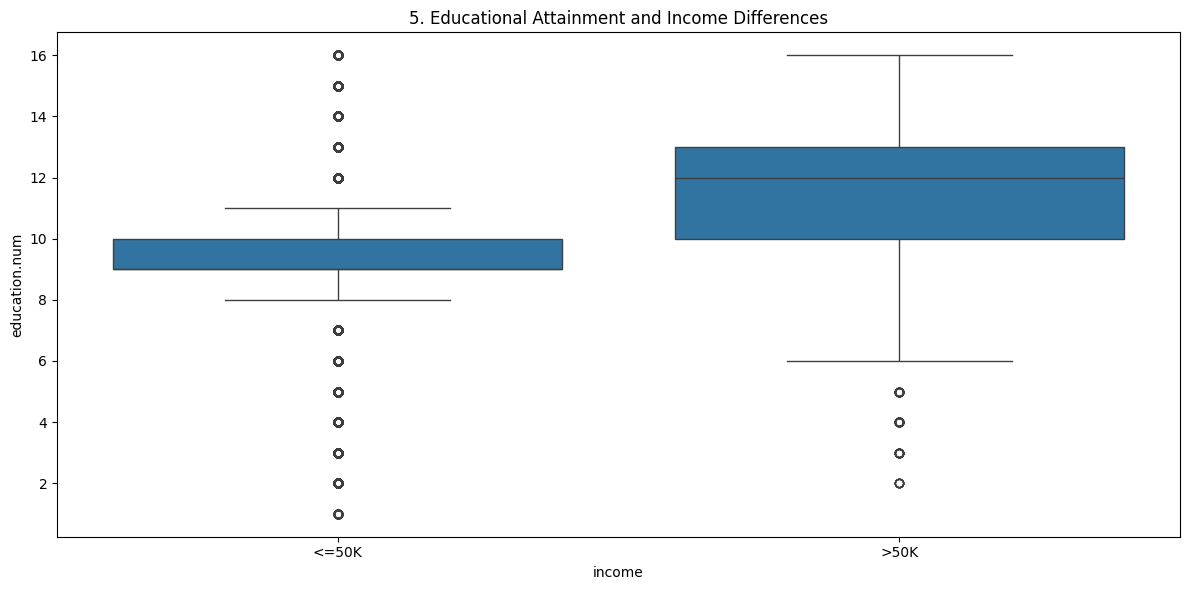

In [17]:
fig = plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='income', y='education.num')
plt.title(f'{plot_no}. Educational Attainment and Income Differences')
show_fig()
plot_no += 1

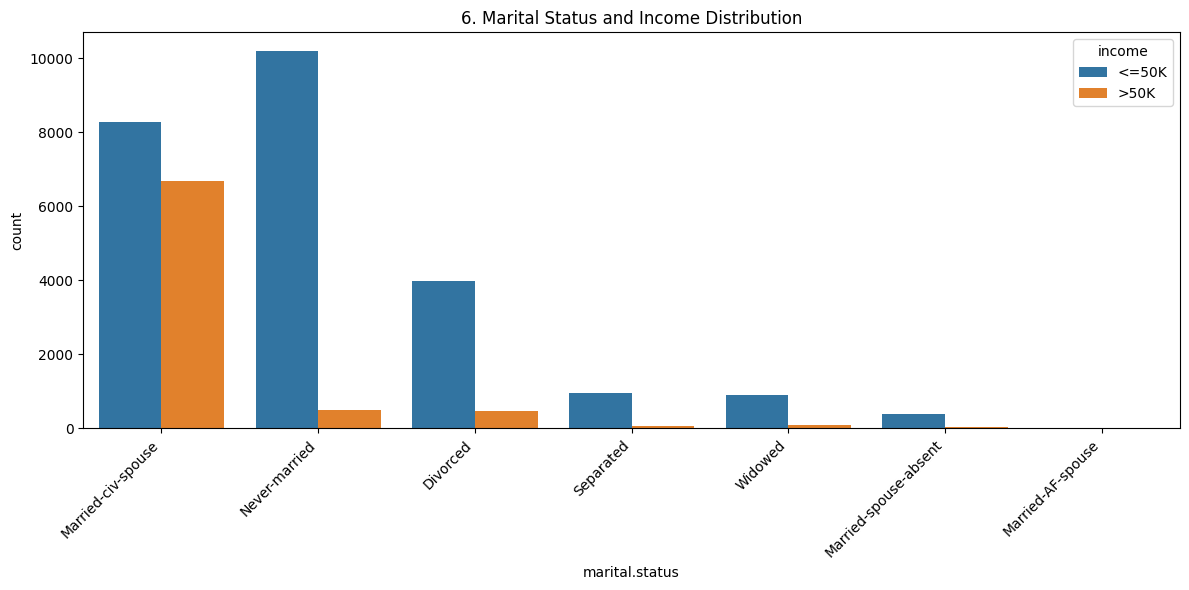

In [18]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='marital.status', hue='income', order=df['marital.status'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Marital Status and Income Distribution')
show_fig()
plot_no += 1

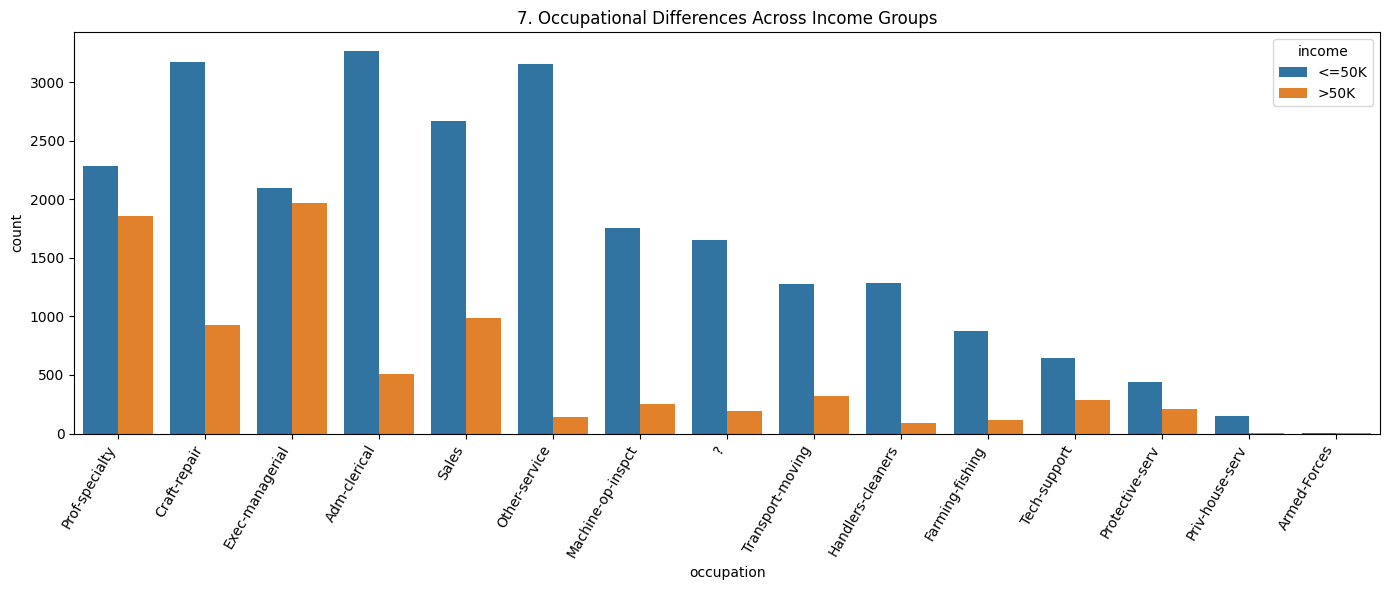

In [19]:
fig = plt.figure(figsize=(14,6))
sns.countplot(data=df, x='occupation', hue='income', order=df['occupation'].value_counts().index)
plt.xticks(rotation=60, ha='right')
plt.title(f'{plot_no}. Occupational Differences Across Income Groups')
show_fig()
plot_no += 1

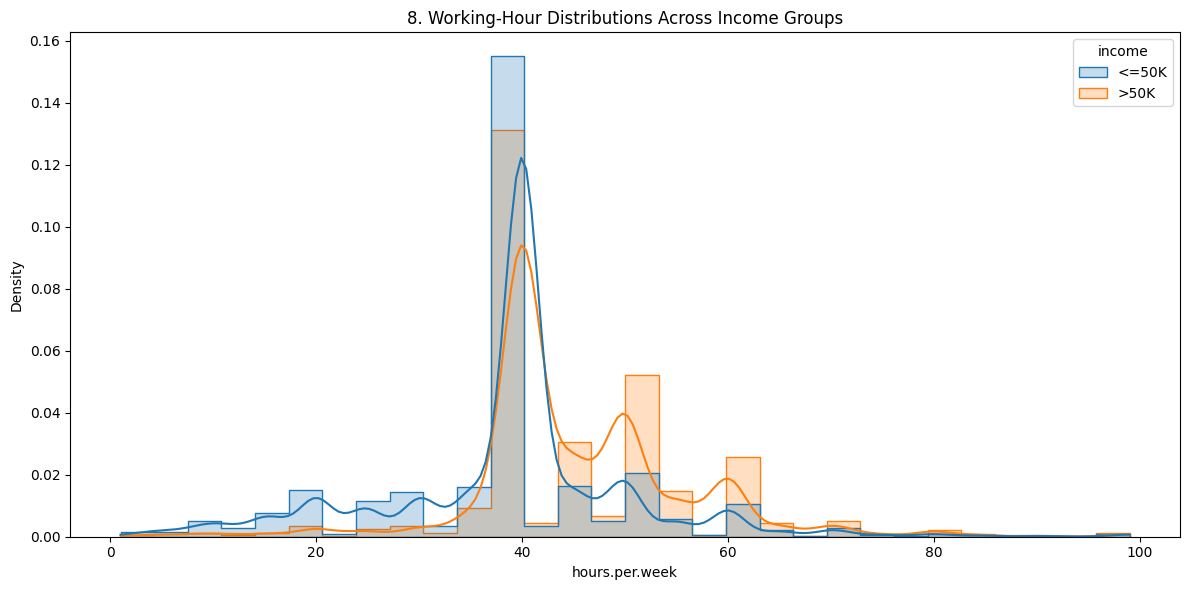

In [20]:
fig = plt.figure(figsize=(12,6))
sns.histplot(data=df, x='hours.per.week', hue='income', bins=30, kde=True, element='step', stat='density', common_norm=False)
plt.title(f'{plot_no}. Working-Hour Distributions Across Income Groups')
show_fig()
plot_no += 1

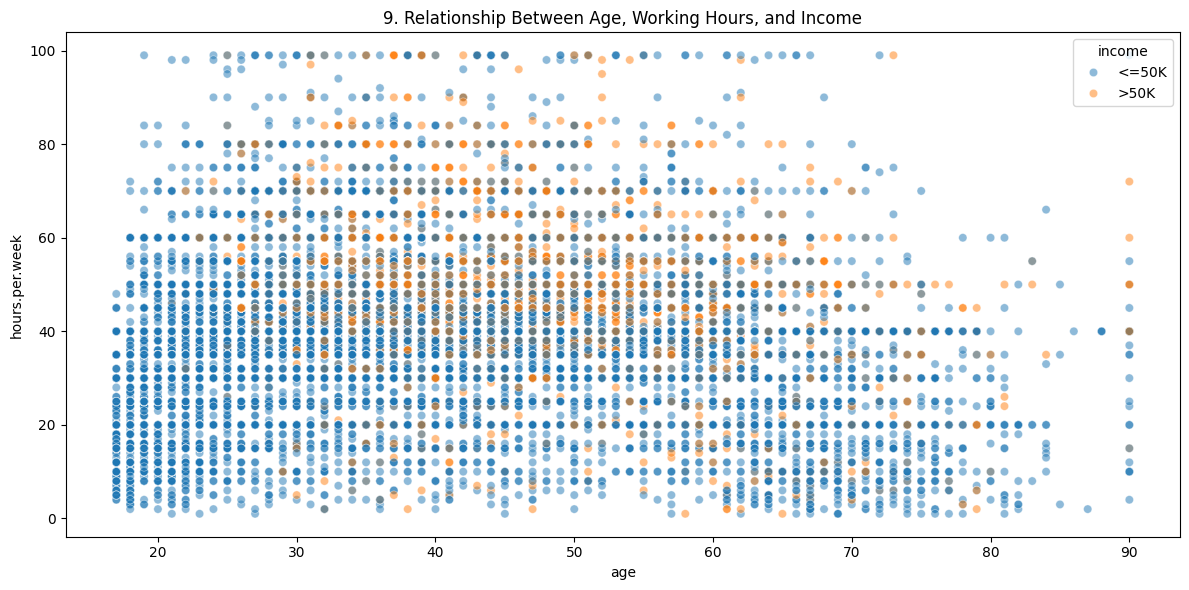

In [21]:
fig = plt.figure(figsize=(12,6))
sns.scatterplot(data=df, x='age', y='hours.per.week', hue='income', alpha=0.5)
plt.title(f'{plot_no}. Relationship Between Age, Working Hours, and Income')
show_fig()
plot_no += 1

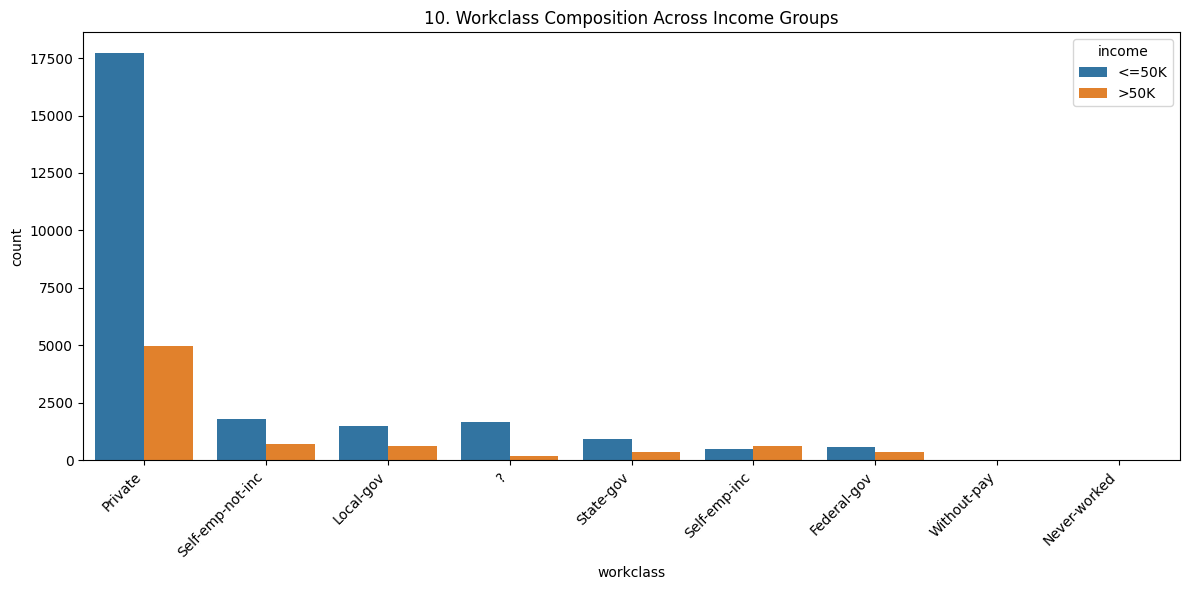

In [22]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='workclass', hue='income', order=df['workclass'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Workclass Composition Across Income Groups')
show_fig()
plot_no += 1

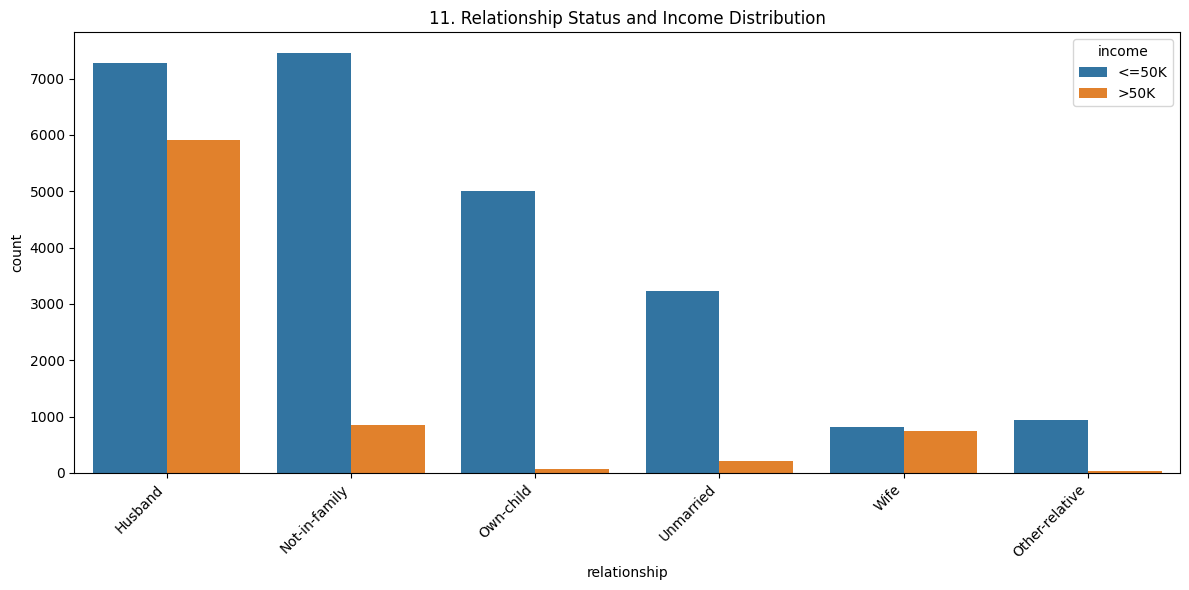

In [23]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='relationship', hue='income', order=df['relationship'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Relationship Status and Income Distribution')
show_fig()
plot_no += 1

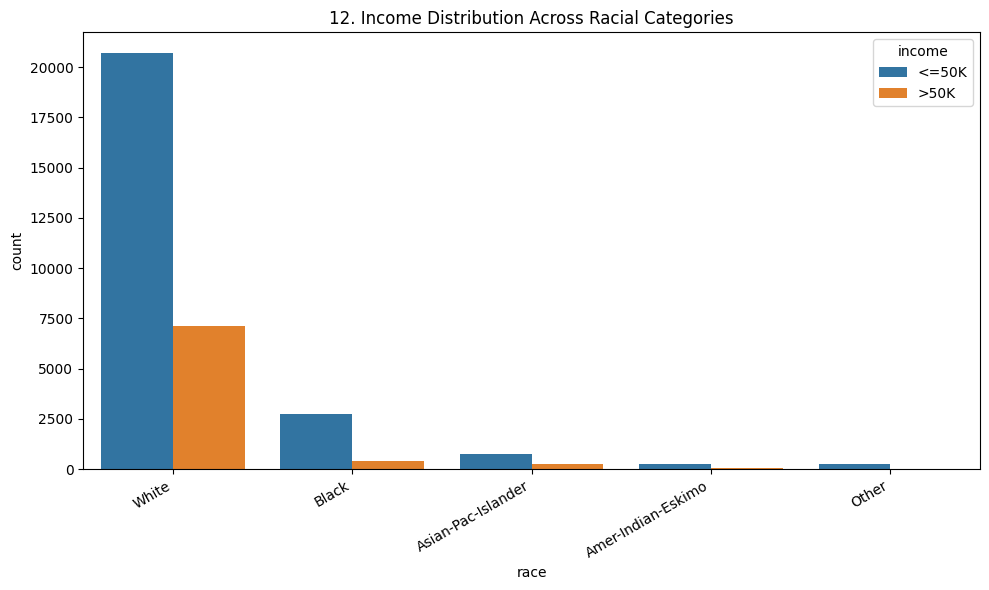

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='race', hue='income', order=df['race'].value_counts().index)
plt.xticks(rotation=30, ha='right')
plt.title(f'{plot_no}. Income Distribution Across Racial Categories')
show_fig()
plot_no += 1

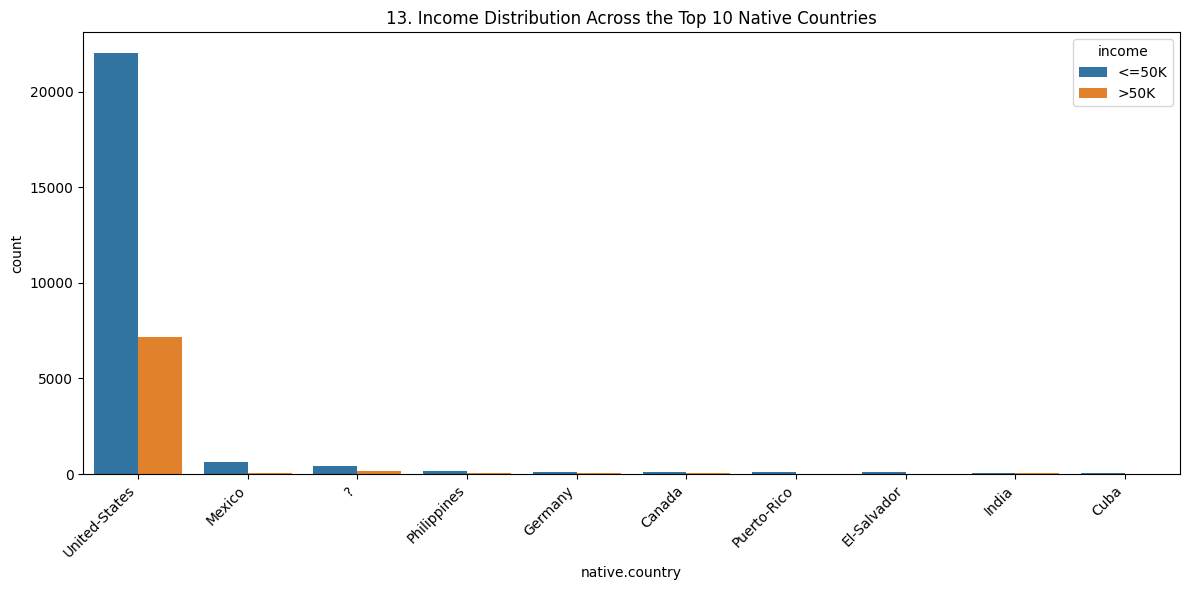

In [25]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='native.country', hue='income', order=df['native.country'].value_counts().head(10).index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Income Distribution Across the Top 10 Native Countries')
show_fig()
plot_no += 1

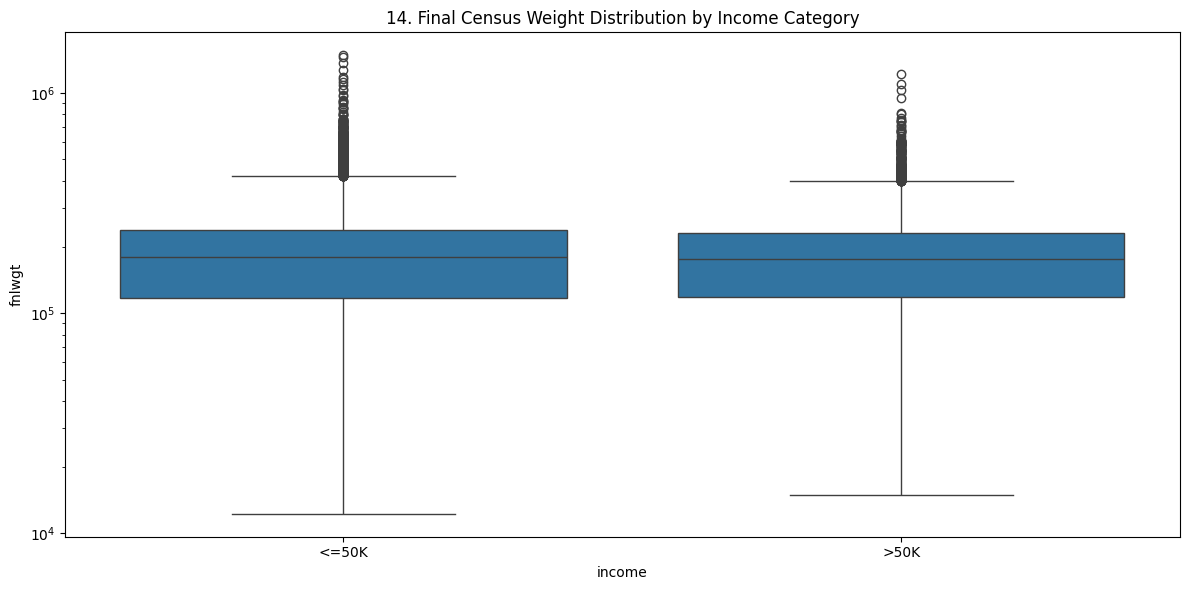

In [26]:
fig = plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='income', y='fnlwgt')
plt.yscale('log')
plt.title(f'{plot_no}. Final Census Weight Distribution by Income Category')
show_fig()
plot_no += 1

<Figure size 1200x600 with 0 Axes>

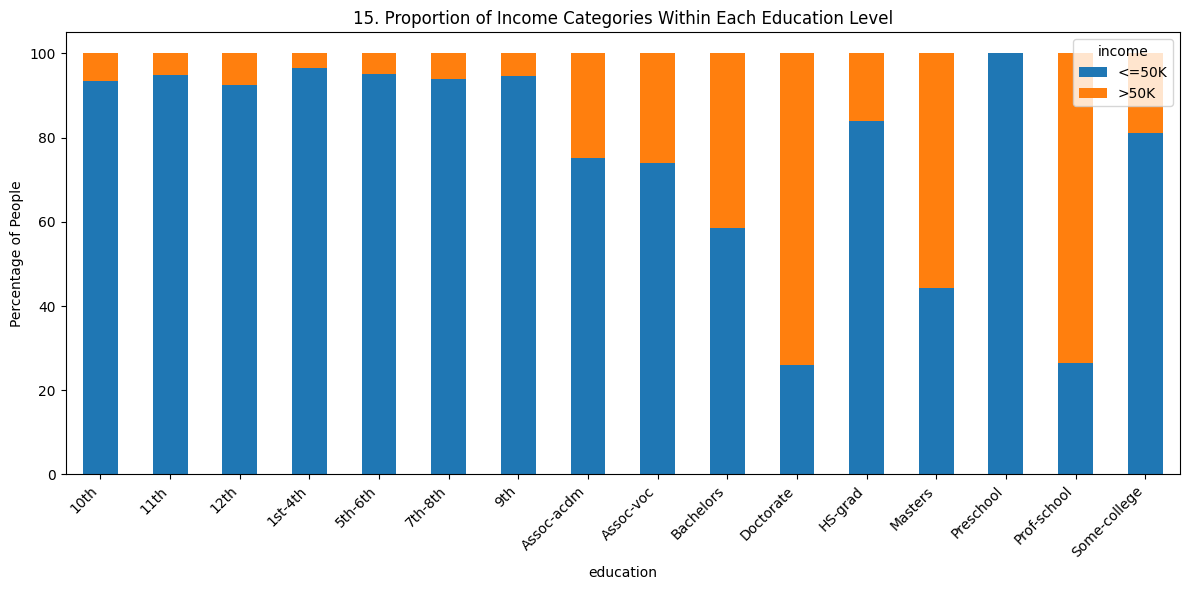

In [27]:
fig = plt.figure(figsize=(12,6))
income_rate = pd.crosstab(df['education'], df['income'], normalize='index') * 100
income_rate.plot(kind='bar', stacked=True, figsize=(12,6))
plt.ylabel('Percentage of People')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Proportion of Income Categories Within Each Education Level')
show_fig()
plot_no += 1

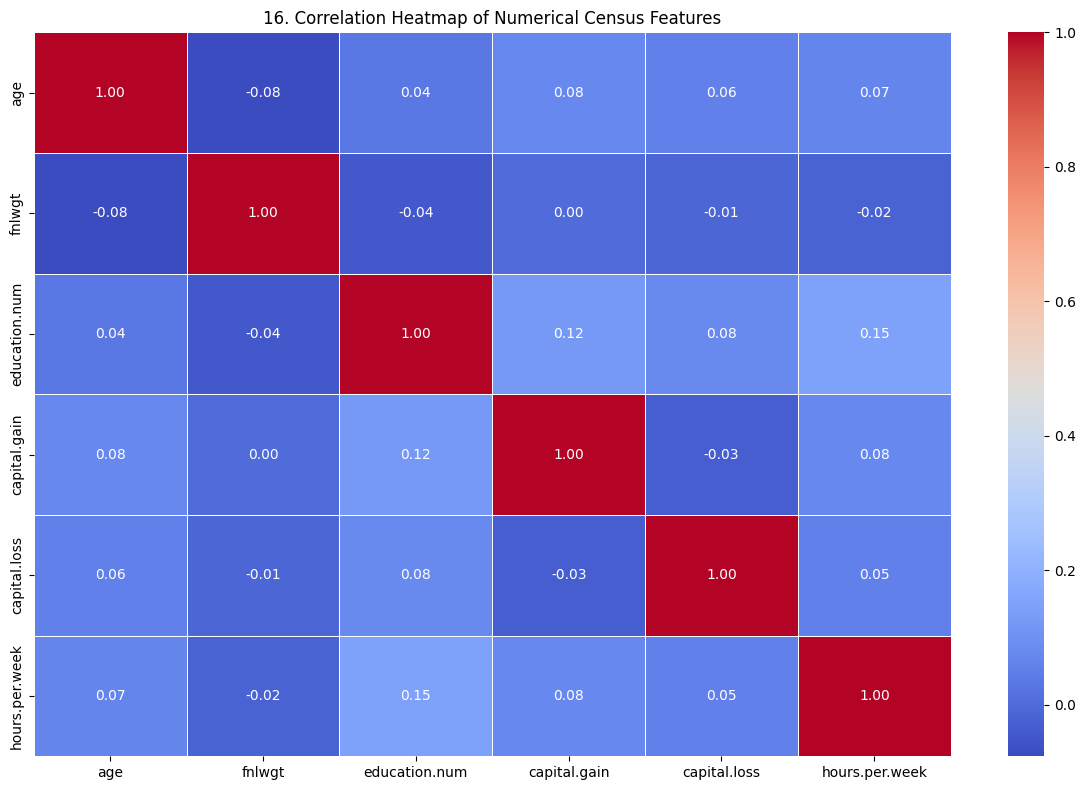

In [28]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Census Features')
show_fig()
plot_no += 1

# Model Training

## Clean missing values and prepare dataset

In [29]:
data = df.copy()
data = data.astype(object)
data = data.replace(r'^\s*\?+\s*$', np.nan, regex=True)
data = data.replace(r'^\s*$', np.nan, regex=True)
data = data.replace({pd.NA: np.nan, None: np.nan})

## Remove rows with missing target values

In [30]:
data = data.dropna(subset=['income'])
data['income'] = data['income'].astype(str).str.strip()
data = data[data['income'] != '']

## Convert numerical columns to numeric values

In [31]:
num_candidates = ['age', 'fnlwgt', 'education.num', 'capital.gain',
                  'capital.loss', 'hours.per.week']
for col in num_candidates:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

## Prepare features and target

In [32]:
X = data.drop(columns=['income'])
y = data['income']

## Identify numerical and categorical columns

In [33]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Convert categorical values to consistent strings

In [34]:
for col in cat_cols:
    X[col] = X[col].map(lambda v: np.nan if pd.isna(v) else str(v).strip())

## Build preprocessing pipelines

In [35]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Split the dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Create and train the model

In [37]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, solver='liblinear'))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Generate predictions

In [38]:
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)

## Print accuracy scores

In [39]:
print(f"Training Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Testing Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Training Accuracy: 0.8509
Testing Accuracy: 0.8526

Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.60      0.66      1568

    accuracy                           0.85      6513
   macro avg       0.81      0.77      0.78      6513
weighted avg       0.85      0.85      0.85      6513



## Plot the confusion matrix

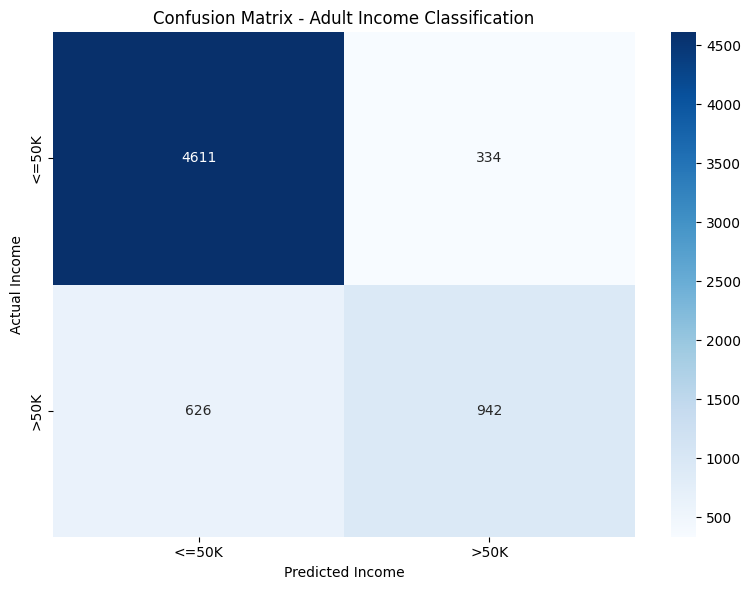

In [40]:
fig = plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')
plt.title('Confusion Matrix - Adult Income Classification')
plt.tight_layout()
plt.show()